<a href="https://colab.research.google.com/github/mahmoud-elmowafy/real-estate-price-prediction-svr/blob/main/real_estate_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Real estate.csv to Real estate.csv


In [ ]:
import pandas as pd

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [ ]:
print("Dataset Shape:", df.shape)
print(df.columns.tolist())

Dataset Shape: (414, 8)
['No', 'X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']


In [ ]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB

Statistical Summary:


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000



Missing Values:
No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

Duplicate Rows:
0


In [ ]:
# Create a copy
df_clean = df.copy()

# Drop ID column
df_clean.drop(columns=['No'], inplace=True)

# Check dataset
print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:", df_clean.isnull().sum().sum())

print("\nDuplicates:", df_clean.duplicated().sum())

display(df_clean.head())

Dataset Shape: (414, 7)

Missing Values: 0

Duplicates: 0


,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


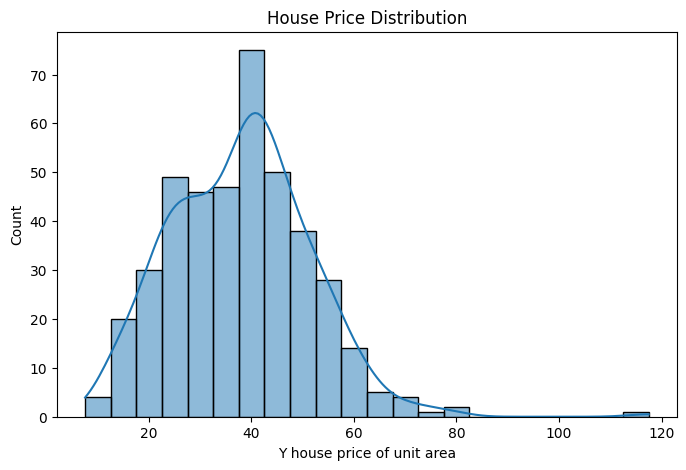

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df_clean['Y house price of unit area'],
    kde=True
)

plt.title('House Price Distribution')
plt.show()

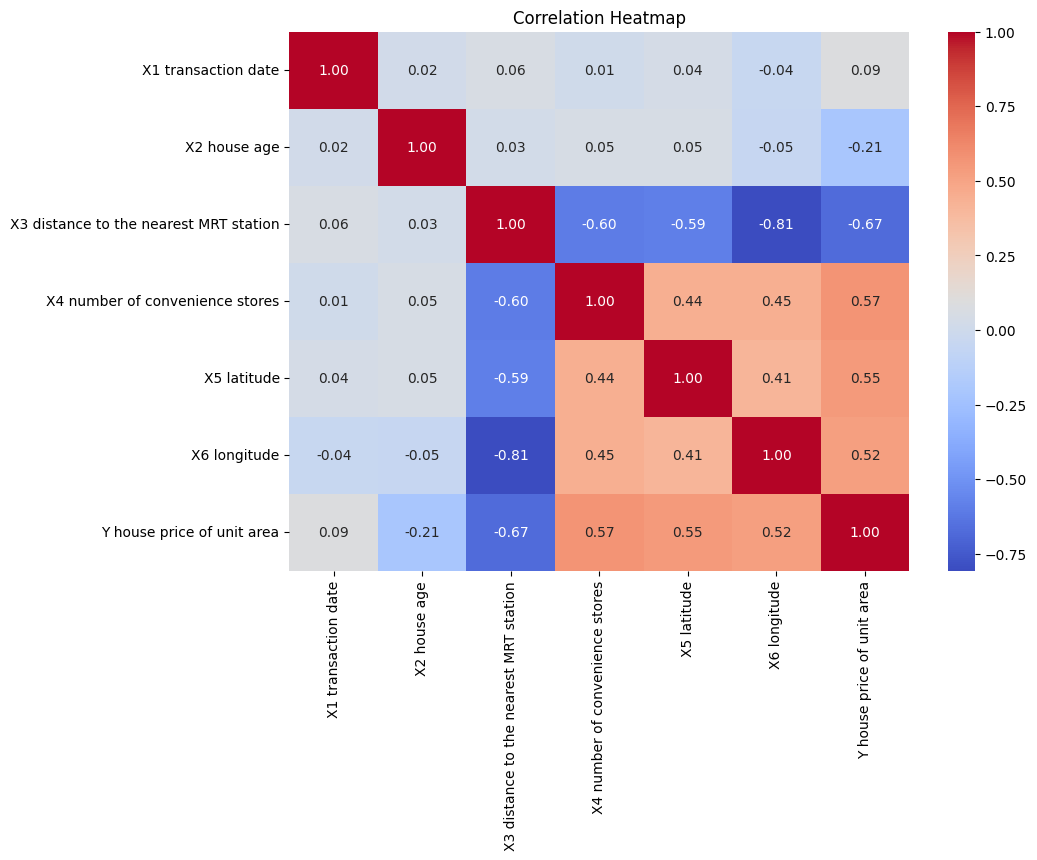

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clean.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

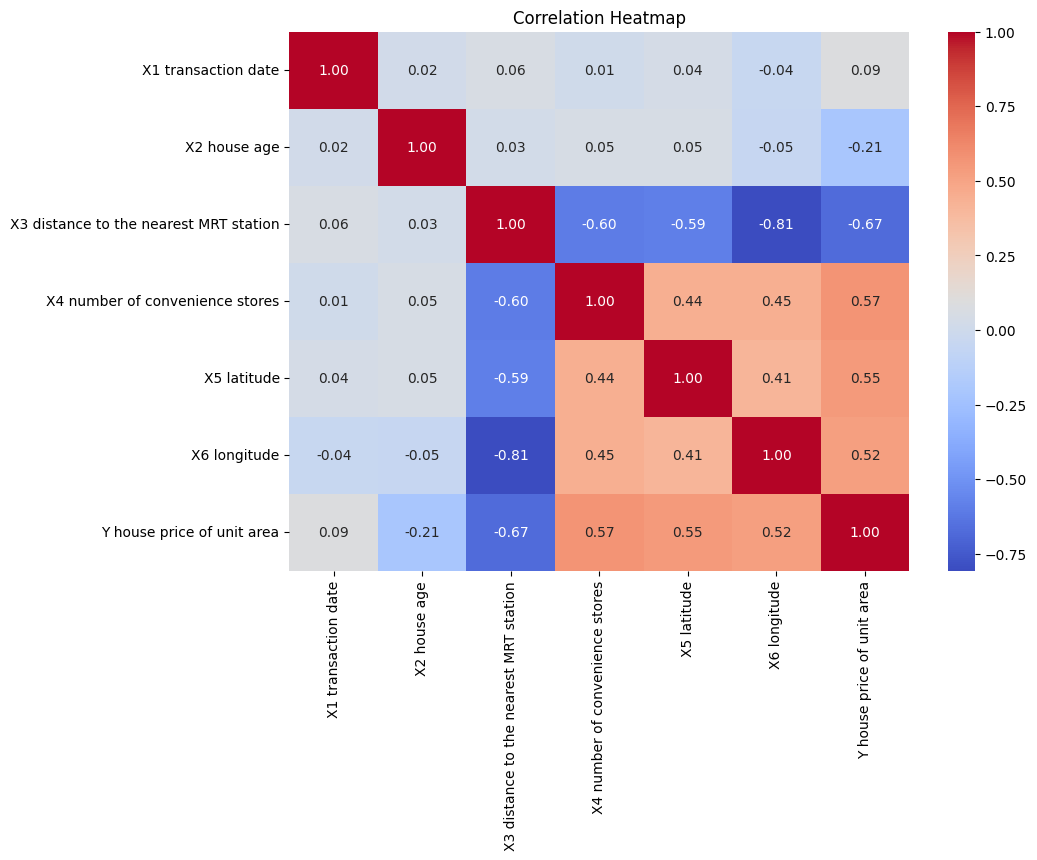

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clean.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

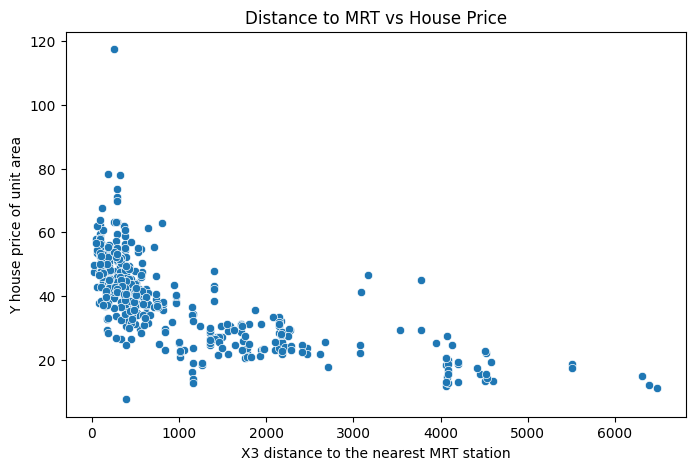

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x='X3 distance to the nearest MRT station',
    y='Y house price of unit area'
)

plt.title('Distance to MRT vs House Price')
plt.show()

In [ ]:
print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicates:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

Dataset Shape: (414, 7)

Missing Values:
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

Duplicates:
0

Data Types:
X1 transaction date                       float64
X2 house age                              float64
X3 distance to the nearest MRT station    float64
X4 number of convenience stores             int64
X5 latitude                               float64
X6 longitude                              float64
Y house price of unit area                float64
dtype: object


In [ ]:
# Define Features
X = df_clean.drop(
    columns=['Y house price of unit area']
)

# Define Target
y = df_clean['Y house price of unit area']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (414, 6)
Target Shape: (414,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (331, 6)
Testing Features: (83, 6)
Training Target: (331,)
Testing Target: (83,)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


In [ ]:
from sklearn.svm import SVR

# Create SVR Model
svr_model = SVR(
    kernel='rbf',
    C=1.0,
    epsilon=0.1,
    gamma='scale'
)

# Train Model
svr_model.fit(X_train_scaled, y_train)

print("SVR Model Trained Successfully!")

SVR Model Trained Successfully!


In [ ]:
y_pred = svr_model.predict(X_test_scaled)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[45.1 42.3 52.2 37.3 22.8 36.3 53.  51.4 16.1 59. ]

Predicted Values:
[46.66381415 40.0967269  41.92524643 37.82577058 26.80720683 40.49395443
 43.767816   45.50611191 25.57605884 45.93768641]


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("SVR Model Evaluation")
print("--------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

SVR Model Evaluation
--------------------
MAE: 5.471054955297876
MSE: 57.53634210849571
RMSE: 7.5852713931998315
R2 Score: 0.6570312963158411
